# Primer experimento de pronóstico con HistGradientBoosting

**¿Podemos empezar con los datos que tenemos sin inventar los años faltantes?** Sí:
este notebook entrena y evalúa PM2.5 y PM10 con la semana continua del piloto RMCAB.
Compara persistencia, HGB con entradas faltantes nativas y HGB con mediana aprendida
solo del entrenamiento. Las mediciones originales permanecen intactas.

**Estado: experimento histórico, no modelo desplegado ni pronóstico para hoy.**
Los 17 reportes incluidos no son once años completos; diez son fechas aisladas y
solo 2025 aporta siete días consecutivos. La validación final de calidad de los
reportes no está verificada. Una semana tampoco representa las temporadas del año.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'research').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'research').is_dir():
    raise RuntimeError('Ejecuta desde la raíz del repositorio o notebooks/.')
sys.path.insert(0, str(ROOT))

# El adaptador es pandas puro: reutiliza el contrato y el manifiesto sin importar Django.
from dash2.rmcab_data import load_samples
from research.air_quality import VARIABLES
from research.forecast_experiment import MODEL_PARAMS, feature_columns, run_pilot_benchmark

DATA_PATH = ROOT / 'data/samples/rmcab_pilot_2015_2025.csv'
SOURCE_MANIFEST = DATA_PATH.with_suffix('.sources.json')
initial_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
data = load_samples(DATA_PATH)
versions = {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']}
display(pd.Series(versions, name='version'))

numpy           1.26.4
pandas           2.3.3
scikit-learn     1.7.2
matplotlib      3.10.7
Name: version, dtype: object

## 1. Qué significa completar datos

| Tratamiento | Uso en este experimento |
|---|---|
| Ausencia conservada como NaN | HGB aprende a tratar entradas faltantes. No requiere llenar todo el CSV. |
| Mediana de entrenamiento | Alternativa para predictores, dentro del pipeline y ajustada de nuevo en cada corte. |
| Datos sintéticos | Podrían servir para simulación separada; no se añaden como mediciones ni aumentan la evidencia histórica. |
| Objetivo futuro faltante | Se excluye; nunca se fabrica para entrenar o evaluar el pronóstico. |

No interpolamos entre el pasado y el futuro antes de dividir los datos. No
extendemos el CSV desde 2015 hasta 2025 rellenando años sin observaciones.

In [2]:
coverage = data.groupby(data.report_date.dt.year).agg(
    report_days=('report_date', 'nunique'), station_hours=('datetime', 'size'),
    PM25_observed=('pm_25', 'count'), PM10_observed=('pm_10', 'count'))
display(coverage)

cohort = data.loc[data.report_date.between('2025-02-03', '2025-02-09')].copy()
assert cohort.report_date.nunique() == 7, 'El piloto esperado tiene siete reportes diarios consecutivos.'
display(pd.DataFrame({
    'observed': [cohort[v].notna().sum() for v in VARIABLES],
    'missing_or_range_review': [cohort[v].isna().sum() for v in VARIABLES],
}, index=VARIABLES))
print('Cohorte:', cohort.datetime.min(), 'a', cohort.datetime.max())
print('Estaciones:', cohort.station_id.nunique(), '| filas de estación/hora:', len(cohort))

,report_days,station_hours,PM25_observed,PM10_observed
report_date,,,,
2015,1,288,203,262
2016,1,312,260,284
2017,1,312,286,284
2018,1,288,262,259
2019,1,336,285,312
2020,1,336,306,273
2021,1,432,400,383
2022,1,456,417,383
2023,1,456,378,372


,observed,missing_or_range_review
pm_25,2751,441
pm_10,2763,429
temperature,2516,676
humidity,1823,1369


Cohorte: 2025-02-03 01:00:00-05:00 a 2025-02-10 00:00:00-05:00
Estaciones: 19 | filas de estación/hora: 3192


## 2. Variables, horizontes y cortes

Cada contaminante se modela por separado. Entradas: estación, PM2.5, PM10,
temperatura y humedad observadas en el origen, rezagos del objetivo a 1 y 24 horas,
hora/mes cíclicos y día de la semana. Los rezagos usan coincidencias de hora exacta,
no desplazamientos de filas a través de huecos. El mes es constante en este piloto.
No se usa meteorología futura observada, ni se añaden indicadores derivados de y.

Se comparan horizontes puntuales a 1, 24, 48 y 72 horas, con hasta tres ventanas
consecutivas de 24 horas de origen por horizonte. Todo objetivo de entrenamiento
debe ocurrir **antes del primer origen de validación**; todas las estaciones de una
hora pertenecen al mismo bloque temporal. Se excluyen estaciones no vistas en train.

Como umbral operativo del experimento se exigen al menos 48 horas distintas de
origen y 200 filas de entrenamiento. No es una garantía estadística de suficiencia.
Las ventanas que no cumplen se omiten explícitamente. Persistencia y HGB se evalúan
con los mismos objetivos reales y una lectura actual del contaminante disponible.

Parámetros fijos, sin búsqueda sobre validación. `early_stopping=False` evita una
partición aleatoria interna. Los valores publicados se consideran disponibles en
el origen: no tenemos un archivo histórico de retrasos y revisiones del portal.

In [3]:
CONFIG = dict(targets=('pm_25', 'pm_10'), horizons=(1, 24, 48, 72),
              n_folds=3, validation_hours=24, min_train_hours=48, min_train_rows=200)
display(pd.Series(MODEL_PARAMS, name='HGB_parameter'))
result = run_pilot_benchmark(cohort, **CONFIG)
folds, scores = result['folds'], result['scores']
predictions, per_station = result['predictions'], result['per_station']
display(folds[['target', 'horizon_hours', 'fold', 'train_origin_hours',
               'train_rows', 'validation_rows', 'status', 'reason']])
assert not predictions.empty
evaluated = folds.loc[folds.status.eq('evaluated')]
assert (evaluated.train_target_max < evaluated.validation_origin_start).all()
print('Ventanas evaluadas:', len(evaluated), '| omitidas:', folds.status.eq('skipped').sum())

max_iter                80
max_leaf_nodes          15
min_samples_leaf        20
learning_rate         0.05
l2_regularization      1.0
early_stopping       False
random_state            42
Name: HGB_parameter, dtype: object

,target,horizon_hours,fold,train_origin_hours,train_rows,validation_rows,status,reason
0,pm_25,1,1,94,1338,430,evaluated,exploratory_short_history
1,pm_25,1,2,118,1790,454,evaluated,exploratory_short_history
2,pm_25,1,3,142,2244,451,evaluated,exploratory_short_history
3,pm_25,24,1,48,573,332,evaluated,exploratory_short_history
4,pm_25,24,2,72,945,406,evaluated,exploratory_short_history
5,pm_25,24,3,96,1372,426,evaluated,exploratory_short_history
6,pm_25,48,1,0,0,0,skipped,insufficient_past_training_data
7,pm_25,48,2,24,273,308,skipped,insufficient_past_training_data
8,pm_25,48,3,48,577,330,evaluated,exploratory_short_history
9,pm_25,72,1,0,0,0,skipped,insufficient_past_training_data


Ventanas evaluadas: 14 | omitidas: 10


## 3. Error sobre observaciones reales

MAE y RMSE se expresan en **µg/m³**, no como un porcentaje de exactitud.
`MAE_skill_vs_persistence > 0` indica menor MAE que repetir el valor actual;
un número negativo indica peor resultado. Se agrupan errores de los puntos
validados, sin promediar promedios de estaciones de distinto tamaño.

Las ventanas y las horas están correlacionadas y el piloto es corto. Estos valores
son resultados exploratorios; no prueban generalización anual, a otras estaciones
o barrios, ni constituyen una evaluación final independiente para publicar el modelo.

In [4]:
display(scores.round(3))
comparison = scores.pivot(index=['target', 'horizon_hours'], columns='method', values='MAE_ug_m3')
comparison['native_beats_persistence'] = comparison.hgb_native_missing < comparison.persistence
comparison['native_beats_median'] = comparison.hgb_native_missing < comparison.hgb_train_median
display(comparison.round(3))
print('Los horizontes sin ventanas válidas no reciben una puntuación inventada.')
display(per_station.sort_values(['target', 'horizon_hours', 'station_id', 'method']).head(18).round(3))

,target,horizon_hours,method,n,MAE_ug_m3,RMSE_ug_m3,baseline_MAE,MAE_skill_vs_persistence
0,pm_10,1,hgb_native_missing,1305,6.792,9.225,6.663,-0.019
1,pm_10,1,hgb_train_median,1305,6.816,9.205,6.663,-0.023
2,pm_10,1,persistence,1305,6.663,9.430,6.663,0.000
3,pm_10,24,hgb_native_missing,1162,11.622,15.552,13.274,0.124
4,pm_10,24,hgb_train_median,1162,11.564,15.498,13.274,0.129
5,pm_10,24,persistence,1162,13.274,17.912,13.274,0.000
6,pm_10,48,hgb_native_missing,349,12.037,15.778,13.662,0.119
7,pm_10,48,hgb_train_median,349,11.928,15.770,13.662,0.127
8,pm_10,48,persistence,349,13.662,17.659,13.662,0.000
9,pm_25,1,hgb_native_missing,1335,4.318,5.588,4.419,0.023


method                hgb_native_missing  hgb_train_median  persistence  \
target horizon_hours                                                      
pm_10  1                           6.792             6.816        6.663   
       24                         11.622            11.564       13.274   
       48                         12.037            11.928       13.662   
pm_25  1                           4.318             4.298        4.419   
       24                          6.400             6.433        8.306   
       48                          6.603             6.610        8.569   

method                native_beats_persistence  native_beats_median  
target horizon_hours                                                 
pm_10  1                                 False                 True  
       24                                 True                False  
       48                                 True                False  
pm_25  1                                  True                False  
       24                                 True                 True  
       48                                 True                 True

Los horizontes sin ventanas válidas no reciben una puntuación inventada.


,target,horizon_hours,station_id,station_name,method,n,MAE_ug_m3,RMSE_ug_m3
0,pm_10,1,1,usaquen,hgb_native_missing,60,5.498,8.170
1,pm_10,1,1,usaquen,hgb_train_median,60,5.470,8.041
2,pm_10,1,1,usaquen,persistence,60,6.198,9.365
3,pm_10,1,11,suba,hgb_native_missing,70,5.507,6.623
4,pm_10,1,11,suba,hgb_train_median,70,5.462,6.580
5,pm_10,1,11,suba,persistence,70,5.833,6.748
6,pm_10,1,13,puente aranda,hgb_native_missing,72,7.011,8.604
7,pm_10,1,13,puente aranda,hgb_train_median,72,6.922,8.593
8,pm_10,1,13,puente aranda,persistence,72,6.222,7.979
9,pm_10,1,17,minambiente,hgb_native_missing,72,7.648,11.426


## 4. Ejemplo visual de evaluación a 24 horas

Se elige por contaminante la estación con más puntos evaluados, no la de menor
error. Cada punto de la curva procede de un origen distinto con una antelación de
24 horas. **No es una curva completa emitida desde un único instante.** Solo aparecen
horas con observación de destino; los huecos mayores de una hora interrumpen la línea.

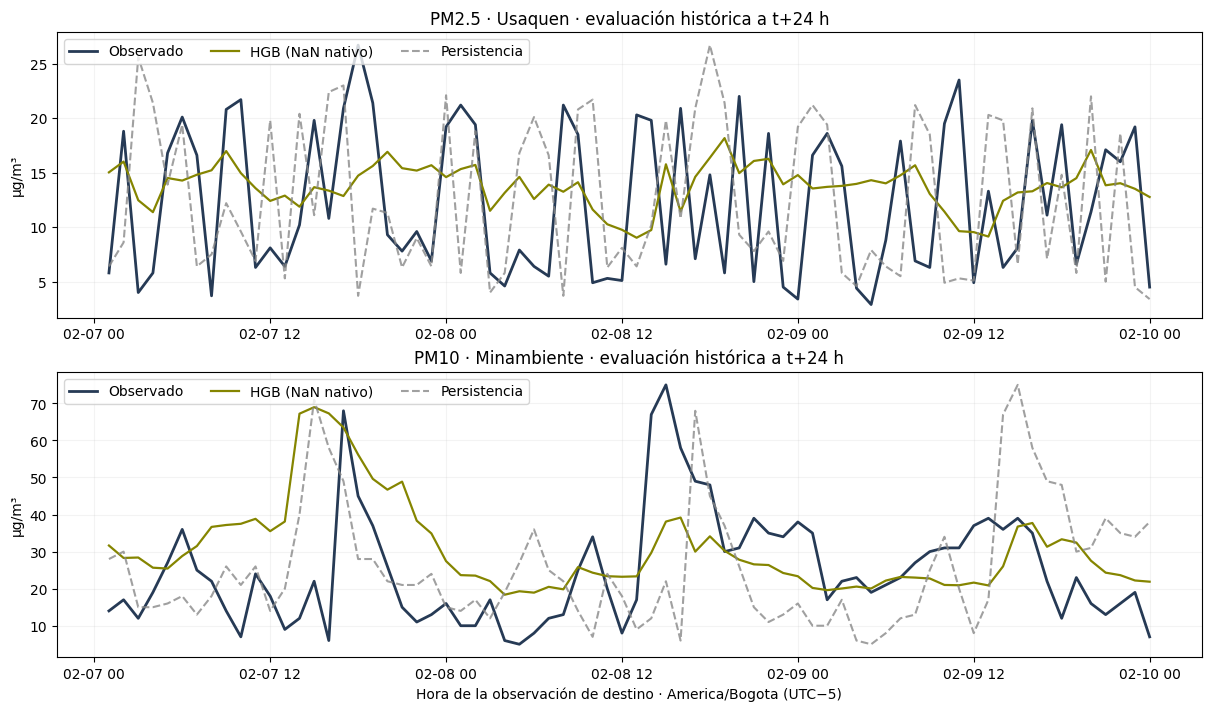

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
for ax, target, label in zip(axes, ('pm_25', 'pm_10'), ('PM2.5', 'PM10')):
    part = predictions.loc[predictions.target.eq(target) & predictions.horizon_hours.eq(24)]
    counts = part.loc[part.method.eq('persistence')].groupby('station_id').size().sort_values(ascending=False, kind='stable')
    if counts.empty:
        ax.text(0.5, 0.5, 'Sin evaluación disponible', ha='center')
        continue
    station = counts.index[0]
    selection = part.loc[part.station_id.eq(station)].sort_values('target_datetime')
    name = selection.station_name.iloc[0].title()
    series = selection.pivot(index='target_datetime', columns='method', values='y_pred')
    truth = selection.drop_duplicates('target_datetime').set_index('target_datetime').y_true
    hourly = pd.date_range(series.index.min(), series.index.max(), freq='h')
    series, truth = series.reindex(hourly), truth.reindex(hourly)
    ax.plot(hourly, truth, color='#263a55', label='Observado', linewidth=2)
    ax.plot(hourly, series.hgb_native_missing, color='#858500', label='HGB (NaN nativo)', linewidth=1.6)
    ax.plot(hourly, series.persistence, color='#888888', label='Persistencia', linestyle='--', alpha=0.8)
    ax.set(title=f'{label} · {name} · evaluación histórica a t+24 h', ylabel='µg/m³')
    ax.grid(alpha=0.15)
    ax.legend(loc='upper left', ncol=3)
axes[-1].set_xlabel('Hora de la observación de destino · America/Bogota (UTC−5)')
plt.show()

## 5. Salidas y límites de uso

Los informes pequeños se versionan; las predicciones detalladas quedan en
`data/processed/` como salida regenerable. Cada predicción conserva URL y SHA256
del reporte de su objetivo observado. No se serializa ni activa un modelo elegido
con esta muestra. El dashboard continúa mostrando las mediciones originales.

Para avanzar: recolectar varios meses continuos y distintas temporadas, repetir
evaluación temporal, reservar un periodo final separado de la selección y estudiar
el error por estación/horizonte. Para pronosticar hoy se necesitan entradas recientes.
La curva completa y sus intervalos requieren una etapa adicional de modelado.

Fuentes metodológicas:
- [HGB: entradas faltantes y parámetros](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)
- [Rezagos y evaluación temporal](https://scikit-learn.org/1.7/auto_examples/applications/plot_time_series_lagged_features.html)
- [Prevención de fuga de información](https://scikit-learn.org/1.7/common_pitfalls.html)

In [6]:
REPORTS = ROOT / 'data/reports/hgb_pilot'
PROCESSED = ROOT / 'data/processed'
REPORTS.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
scores.to_csv(REPORTS / 'scores.csv', index=False)
folds.to_csv(REPORTS / 'temporal_folds.csv', index=False)
per_station.to_csv(REPORTS / 'scores_by_station.csv', index=False)
predictions.to_csv(PROCESSED / 'hgb_pilot_predictions.csv', index=False)
fig.savefig(REPORTS / 'historical_24h_evaluation.png', dpi=150, bbox_inches='tight')
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == initial_hash
metadata = {
    'experiment': 'historical_hgb_pilot_v1',
    'dataset_sha256': initial_hash,
    'source_manifest_sha256': hashlib.sha256(SOURCE_MANIFEST.read_bytes()).hexdigest(),
    'cohort_report_dates': sorted(cohort.report_date.dt.strftime('%Y-%m-%d').unique().tolist()),
    'cohort_station_hours': len(cohort), 'versions': versions,
    'configuration': CONFIG, 'hgb_parameters': MODEL_PARAMS,
    'feature_columns': {target: feature_columns(target) for target in CONFIG['targets']},
    'forecast_models_trained': True, 'deployment_ready': False, 'artifact_exported': False,
    'raw_dataset_modified': False, 'synthetic_observations_created': 0,
    'target_imputation': False, 'predictor_imputation': 'train-only median in comparator; native NaN in main HGB',
    'evaluated_folds': int(folds.status.eq('evaluated').sum()),
    'skipped_folds': int(folds.status.eq('skipped').sum()),
    'negative_hgb_predictions': int(predictions.loc[predictions.method.ne('persistence'), 'y_pred'].lt(0).sum()),
    'limitation': 'One week; same-station retrospective point forecasts; published availability assumed; final source QC unverified; no annual/spatial/live validation.',
}
(REPORTS / 'experiment.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.Series({key: metadata[key] for key in ['forecast_models_trained', 'deployment_ready', 'raw_dataset_modified', 'synthetic_observations_created', 'evaluated_folds', 'skipped_folds']}))

forecast_models_trained            True
deployment_ready                  False
raw_dataset_modified              False
synthetic_observations_created        0
evaluated_folds                      14
skipped_folds                        10
dtype: object